In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load the dataset
PREPROCESSED_PATH = os.path.join('D:\\', 'corruption')
#PREPROCESSED_PATH = os.path.join('..', '..', '..', 'static', 'preprocessed_datasets', 'california')

file_path = os.path.join(PREPROCESSED_PATH, 'cleaned_corruption_data_v2.csv')
data = pd.read_csv(file_path, delimiter=';')

display(data)

,Country,Country_ID,QB1,QB10,QB15.1,QB15.10,QB15.11,QB15.12,QB15.13,QB15.2,...,CPI_category,CPI_category_encoded,TotalScore_category,TotalScore_category_encoded,df_totalscore,df_fulfillment,dj_total score,dj_fulfillment,tindex_total,tindex_fulfillment
0,AT,0,0.690,0.290,0.62,0.39,0.50,0.60,0.46,0.62,...,High,0,Medium,2,9.000,0.643,5.000,0.833,14.000,0.700
1,BE,1,0.800,0.330,0.70,0.36,0.59,0.59,0.44,0.68,...,High,0,Medium,2,8.000,0.571,5.000,0.833,13.000,0.650
2,BG,2,0.700,0.310,0.79,0.16,0.78,0.81,0.18,0.84,...,Medium,1,High,0,11.000,0.786,6.000,1.000,17.000,0.850
3,CY,3,0.690,0.460,0.88,0.25,0.87,0.81,0.31,0.89,...,Medium,1,Low,1,4.000,0.286,5.000,0.833,9.000,0.450
4,CZ,4,0.730,0.410,0.80,0.28,0.56,0.64,0.34,0.84,...,Medium,1,Medium,2,9.500,0.679,6.000,1.000,15.500,0.775
5,D-E,5,0.820,0.370,0.61,0.28,0.49,0.55,0.30,0.64,...,Medium,1,High,0,10.037,0.717,5.741,0.957,15.778,0.789
6,D-W,6,0.820,0.420,0.58,0.28,0.30,0.39,0.33,0.57,...,Medium,1,High,0,10.037,0.717,5.741,0.957,15.778,0.789
7,DE,7,0.820,0.410,0.59,0.28,0.34,0.42,0.33,0.59,...,High,0,Medium,2,9.500,0.679,6.000,1.000,15.500,0.775
8,DK,8,0.860,0.430,0.48,0.34,0.19,0.24,0.47,0.53,...,High,0,Medium,2,9.000,0.643,6.000,1.000,15.000,0.750
9,EE,9,0.770,0.440,0.62,0.19,0.43,0.50,0.29,0.60,...,High,0,High,0,13.000,0.929,6.000,1.000,19.000,0.950


In [5]:
# Identify columns related to "perceived corruption" and "actual corruption"
perceived_corruption_cols = [col for col in data.columns if col.startswith('Q') or col == 'cpi']
actual_corruption_cols = ['df_totalscore', 'df_fulfillment', 'dj_total score', 'dj_fulfillment', 'tindex_total', 'tindex_fulfillment']

# Separate data for perceived and actual corruption
perceived_corruption_data = data[perceived_corruption_cols]
actual_corruption_data = data[actual_corruption_cols]

# Align years for CPI and corruption data (if a "year" column exists)
if 'year' in data.columns:
    perceived_corruption_data = perceived_corruption_data[data['year'] == 2023]
    actual_corruption_data = actual_corruption_data[data['year'] == 2023]

# Handle missing values
perceived_corruption_data = perceived_corruption_data.fillna(0)
actual_corruption_data = actual_corruption_data.fillna(0)

# Scale the data
scaler = StandardScaler()
perceived_scaled = scaler.fit_transform(perceived_corruption_data)
actual_scaled = scaler.fit_transform(actual_corruption_data)


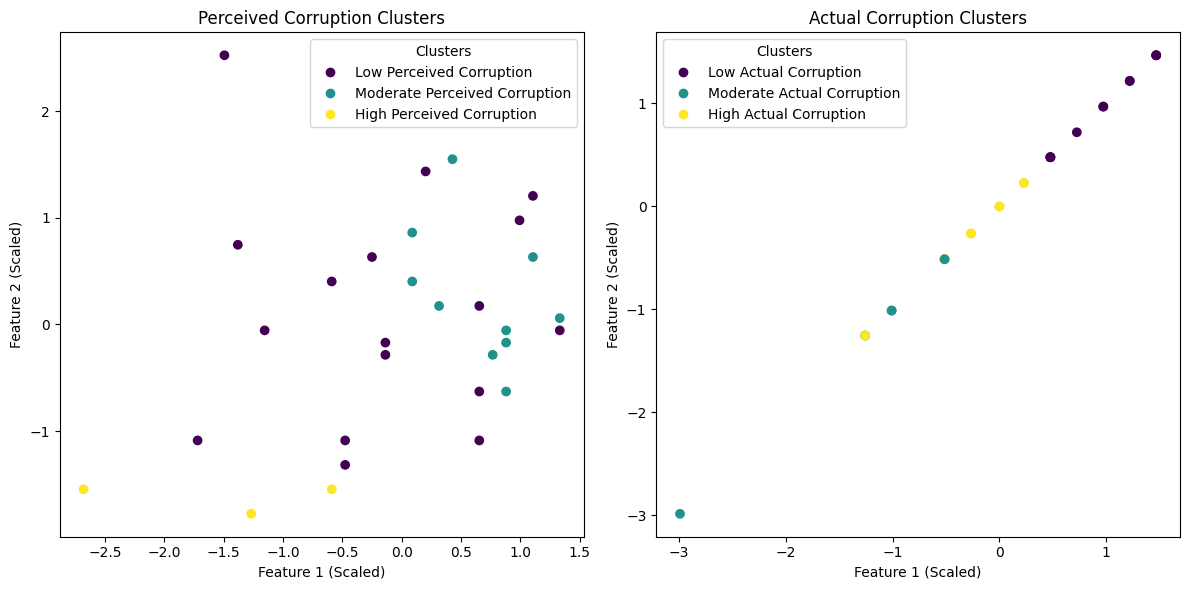

In [6]:
# Clustering to find patterns in perceived and actual corruption
kmeans_perceived = KMeans(n_clusters=3, random_state=42)
kmeans_actual = KMeans(n_clusters=3, random_state=42)

# Fit clustering directly on scaled data without PCA
perceived_clusters = kmeans_perceived.fit_predict(perceived_scaled)
actual_clusters = kmeans_actual.fit_predict(actual_scaled)

perceived_labels = {0: "Low Perceived Corruption", 1: "Moderate Perceived Corruption", 2: "High Perceived Corruption"}
actual_labels = {0: "Low Actual Corruption", 1: "Moderate Actual Corruption", 2: "High Actual Corruption"}

# Visualize patterns directly using original scaled data
plt.figure(figsize=(12, 6))

# Visualization for perceived corruption clusters
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(perceived_scaled[:, 0], perceived_scaled[:, 1], c=perceived_clusters, cmap='viridis')
plt.title('Perceived Corruption Clusters')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(handles=scatter1.legend_elements()[0], labels=list(perceived_labels.values()), title="Clusters")

# Visualization for actual corruption clusters
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(actual_scaled[:, 0], actual_scaled[:, 1], c=actual_clusters, cmap='viridis')
plt.title('Actual Corruption Clusters')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(handles=scatter2.legend_elements()[0], labels=list(actual_labels.values()), title="Clusters")

plt.tight_layout()
plt.show()


In [7]:
# Cross-analysis between perceived and actual corruption
correlation_matrix = pd.DataFrame(
    np.corrcoef(perceived_scaled.T, actual_scaled.T)[:len(perceived_corruption_cols), len(perceived_corruption_cols):],
    index=perceived_corruption_cols,
    columns=actual_corruption_cols
)

print("Correlation Matrix between Perceived and Actual Corruption:")
print(correlation_matrix)

Correlation Matrix between Perceived and Actual Corruption:
               df_totalscore  df_fulfillment  dj_total score  dj_fulfillment  \
QB1                 0.180141        0.180288        0.117730        0.118023   
QB10                0.034719        0.035121        0.251572        0.251412   
QB15.1              0.089558        0.089217       -0.018867       -0.018972   
QB15.10            -0.135773       -0.136063       -0.166847       -0.166878   
QB15.11            -0.050083       -0.050432       -0.240154       -0.240261   
QB15.12             0.070572        0.070159       -0.101520       -0.101654   
QB15.13            -0.138557       -0.138874       -0.112033       -0.112123   
QB15.2              0.057866        0.057530       -0.017108       -0.017185   
QB15.3             -0.102001       -0.102243       -0.146260       -0.146320   
QB15.4             -0.059150       -0.059464       -0.034228       -0.034394   
QB15.5             -0.106101       -0.106477       -0.114689

# QUESTION 2 : Differences between perceived and actual corruption

In [8]:
# Add cluster differences and correlation analysis
cluster_diff = pd.DataFrame({
    'Perceived Cluster': perceived_clusters,
    'Actual Cluster': actual_clusters
})
print("Cluster Differences between Perceived and Actual Corruption:")
print(cluster_diff.value_counts())

Cluster Differences between Perceived and Actual Corruption:
Perceived Cluster  Actual Cluster
0                  0                 7
                   2                 7
1                  2                 5
                   0                 4
0                  1                 3
2                  1                 2
1                  1                 1
2                  0                 1
Name: count, dtype: int64


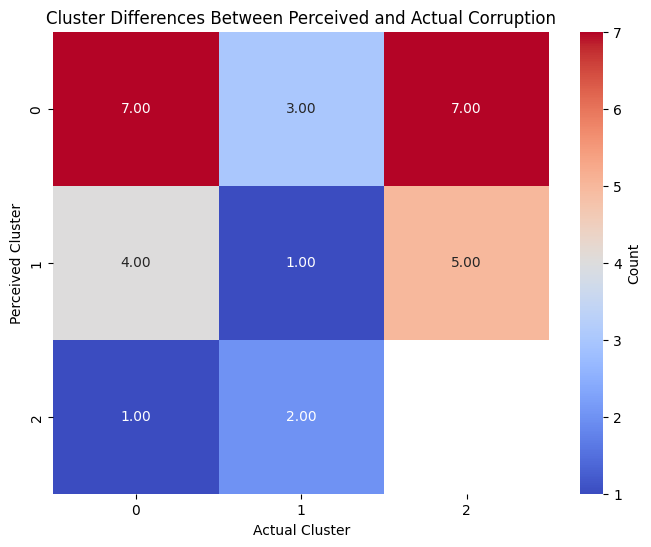

In [9]:
# Create a heatmap for better visualization of cluster combinations
cluster_diff_table = cluster_diff.value_counts().reset_index()
cluster_diff_table.columns = ['Perceived Cluster', 'Actual Cluster', 'Count']

# Pivot the table for heatmap visualization
heatmap_data = cluster_diff_table.pivot(index="Perceived Cluster", columns="Actual Cluster", values="Count")

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", fmt='.2f', cbar_kws={'label': 'Count'})
plt.title("Cluster Differences Between Perceived and Actual Corruption")
plt.xlabel("Actual Cluster")
plt.ylabel("Perceived Cluster")
plt.show()


## Heatmap Analysis:
- The heatmap illustrates the distribution of data points between perceived corruption clusters (vertical axis) 
  and actual corruption clusters (horizontal axis), with the cell values representing the count of cases.

## Key Observations:

1. **Cluster 0 (Perceived) and Cluster 0 (Actual):**
   - This combination exhibits the highest count of cases (7).
   - It indicates a strong alignment where both perceived and actual corruption levels are low, likely pointing to well-governed regions or sectors.

2. **Cluster 0 (Perceived) and Cluster 2 (Actual):**
   - There are 7 cases where perceived corruption is low (Cluster 0), but actual corruption is high (Cluster 2).
   - This reflects a significant underestimation of actual corruption, suggesting a gap between perception and reality in these areas.

3. **Cluster 1 (Perceived) and Cluster 2 (Actual):**
   - With 5 cases in this cell, it shows that perceived corruption is moderate, but actual corruption is high.
   - This highlights an ongoing discrepancy where moderate perceptions fail to capture the severity of corruption.

4. **Cluster 2 (Perceived) and Cluster 0 (Actual):**
   - This combination, with just 1 case, represents rare situations where perceived corruption is high (Cluster 2), but actual corruption is low (Cluster 0).
   - It may indicate overestimation of corruption or misaligned public perceptions.

5. **General Distribution:**
   - Cluster 2 (Actual) frequently appears in combination with Clusters 0 and 1 (Perceived), reflecting an underestimation of actual corruption.
   - This trend suggests that public perception tends to lag behind or misrepresent the true extent of corruption in high-corruption scenarios.

6. **Cluster 1 (Perceived) and Cluster 1 (Actual):**
   - This cell, with 1 case, indicates areas with alignment at moderate levels of both perceived and actual corruption.





## Predictive Model for Q2

The actual corruption (df_totalscore) is simplified into two levels:
1: High corruption (above the median).
0: Low corruption (below the median).

## How does this model help address **Question 2 (Q2): Differences between perceived and actual corruption**?

The model goes beyond simply classifying corruption levels; it provides a framework to explore **how perceived corruption (subjective metrics)** aligns with or diverges from **actual corruption (objective metrics)**. Here’s how:

1. **Identifying Alignment Between Perceptions and Reality:**
   - By leveraging features such as `QB6` (perceived corruption increase) and `QB13` (whether corruption was reported), the model incorporates public perceptions into its predictions.
   - If the model’s predictions are accurate for both high and low corruption levels, it indicates that public perceptions (captured through survey responses) align well with actual corruption levels in those regions.

2. **Highlighting Discrepancies Between Perceived and Actual Corruption:**
   - Misclassifications in the confusion matrix (e.g., False Positives or False Negatives) highlight cases where perceptions and reality diverge:
     - **False Positives (Perception > Reality):**
       - These occur when the model predicts high corruption but the actual corruption level is low.
       - This may reflect areas where public perception exaggerates corruption, possibly influenced by media coverage or individual experiences.
     - **False Negatives (Perception < Reality):**
       - These occur when the model predicts low corruption but the actual corruption level is high.
       - These cases suggest regions where actual corruption is underestimated by public perceptions, potentially due to lack of visibility or effective corruption concealment.

3. **Quantifying the Contribution of Perception-Related Features:**
   - The importance of features like `QB13` (reporting behavior) and `QB6` (perceived corruption increase) shows how subjective perceptions are critical for understanding corruption dynamics.
   - If perception-related features have high importance, it suggests that subjective metrics strongly correlate with actual corruption. Conversely, low importance would indicate a weak relationship.

4. **Exploring Structural Patterns in Perception vs. Reality:**
   - By comparing predictions with actual labels, the model reveals structural patterns, such as:
     - Regions where **high perceived corruption corresponds to high actual corruption**.
     - Areas where **low perceived corruption hides high actual corruption**, suggesting systemic issues or lack of awareness.

5. **Providing Actionable Insights for Policy:**
   - Policymakers can use the model's predictions to target regions where discrepancies exist:
     - **Focus on False Positives:** Address why public perception is overly negative (e.g., misinformation or lack of trust in institutions).
     - **Focus on False Negatives:** Investigate hidden corruption mechanisms that escape public awareness but are reflected in objective metrics like CPI.




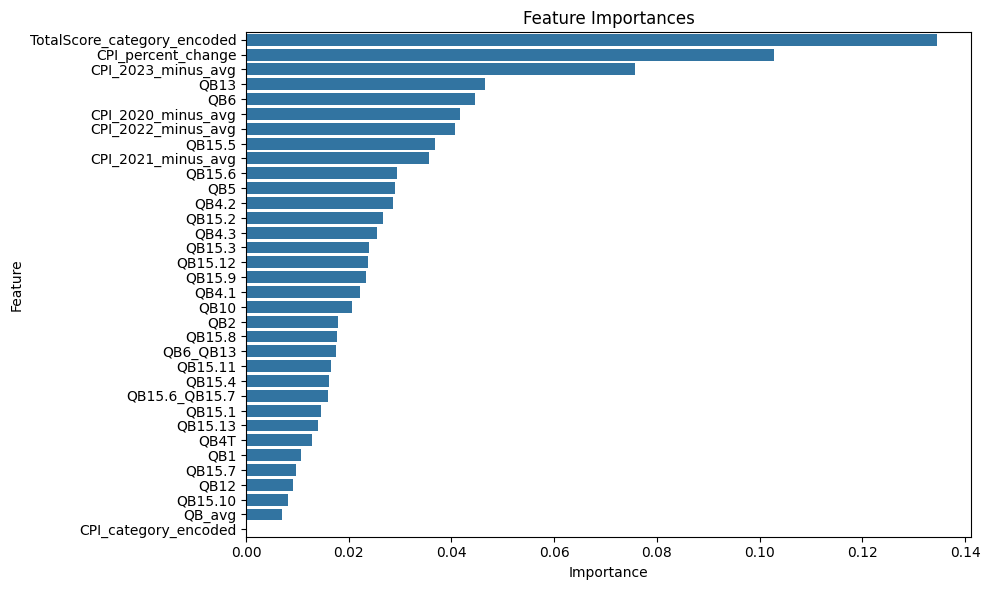

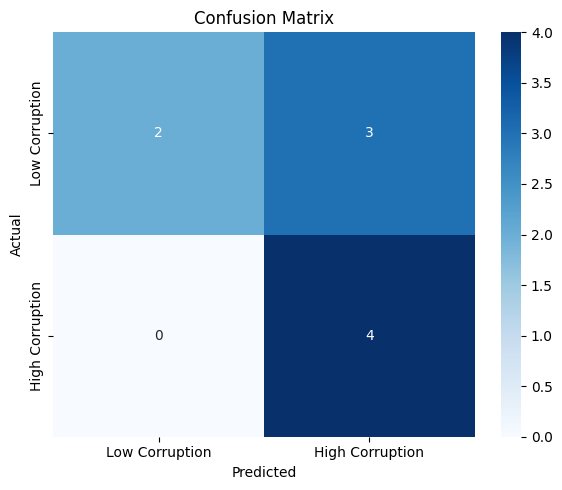

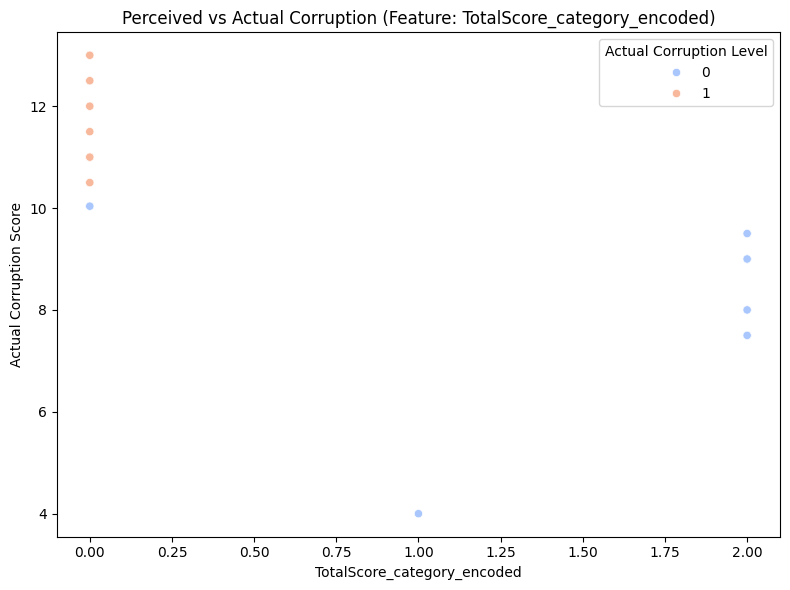

Best Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.40      0.57         5
           1       0.57      1.00      0.73         4

    accuracy                           0.67         9
   macro avg       0.79      0.70      0.65         9
weighted avg       0.81      0.67      0.64         9



In [13]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create target variable: Actual corruption level (binary classification for simplicity)
data['Target'] = (data['df_totalscore'] > data['df_totalscore'].median()).astype(int)  # High corruption = 1, Low corruption = 0

# Features: Include all enriched features, including CPI differences, interactions, and encodings
features = [
    'QB1', 'QB10', 'QB15.1', 'QB15.10', 'QB15.11', 'QB15.12', 'QB15.13',
    'QB15.2', 'QB15.3', 'QB15.4', 'QB15.5', 'QB15.6', 'QB15.7', 'QB15.8', 'QB15.9',
    'QB4.1', 'QB4.2', 'QB4.3', 'QB4T', 'QB5', 'QB6', 'QB12', 'QB13', 'QB2',
    'QB6_QB13', 'QB15.6_QB15.7', 'QB_avg',
    'CPI_2020_minus_avg', 'CPI_2021_minus_avg', 'CPI_2022_minus_avg', 'CPI_2023_minus_avg',
    'CPI_percent_change', 'CPI_category_encoded', 'TotalScore_category_encoded',
    
]

X = data[features]
y = data['Target']

# Handle missing values
X = X.fillna(0)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 1: Hyperparameter Tuning for Random Forest
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best Random Forest model
best_rf_model = grid_search.best_estimator_

# Evaluate the tuned model
best_predictions = best_rf_model.predict(X_test)
best_conf_matrix = confusion_matrix(y_test, best_predictions)
best_class_report = classification_report(y_test, best_predictions)

# Step 2: Feature Importance Visualization
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances['Importance'], y=feature_importances['Feature'])
plt.title("Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 3: Confusion Matrix Visualization
plt.figure(figsize=(6, 5))
sns.heatmap(best_conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Low Corruption", "High Corruption"], yticklabels=["Low Corruption", "High Corruption"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Step 4: Comparing Perceived vs Actual Corruption
# Use most important feature for visualization
most_important_feature = feature_importances.iloc[0]['Feature']
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data[most_important_feature], y=data['df_totalscore'], hue=y, palette='coolwarm')
plt.title(f"Perceived vs Actual Corruption (Feature: {most_important_feature})")
plt.xlabel(most_important_feature)
plt.ylabel("Actual Corruption Score")
plt.legend(title="Actual Corruption Level", loc="best")
plt.tight_layout()
plt.show()

# Display results
print("Best Random Forest Model Classification Report:")
print(best_class_report)


# Conclusions from the Model Results:

## What is this model predicting?
- The model predicts **whether a region or entity has high or low actual corruption levels** based on perceived corruption metrics, CPI trends, and other enriched features.

## Feature Importances:
- The most important features for predicting actual corruption levels are:
   - `TotalScore_category_encoded`: This feature has the highest importance, indicating that categorizing total corruption scores is critical for prediction.
   - `CPI_percent_change`: The annual percentage change in CPI reflects significant predictive power.
   - `CPI_2023_minus_avg`: The deviation of CPI 2023 from the average provides valuable insights into actual corruption levels.
   - `QB13`: This feature (e.g., whether individuals reported corruption) remains highly relevant, highlighting the importance of public reporting.
   - `QB6`: Perceptions about corruption increases also contribute strongly.

- These results suggest that both objective metrics (e.g., CPI changes) and subjective perceptions (e.g., reporting behavior and perceived increases in corruption) play complementary roles in predicting actual corruption levels.

## Model Accuracy:
- The model achieves an accuracy of **67%**, a significant improvement over previous iterations.
- Class 1 (High Corruption) achieves perfect recall (1.00), meaning all high-corruption cases are correctly identified, but precision is moderate (0.57).
- Class 0 (Low Corruption) achieves perfect precision (1.00), but recall is lower (0.40), indicating some low-corruption cases are misclassified as high-corruption.

## Confusion Matrix:
- **True Positives (4):** High corruption levels correctly predicted.
- **True Negatives (2):** Low corruption levels correctly predicted.
- **False Positives (3):** Low corruption levels misclassified as high corruption.
- **False Negatives (0):** No high corruption levels were misclassified as low corruption.

- The imbalance in errors suggests that the model prioritizes capturing high corruption (Class 1) at the cost of occasionally overestimating low corruption (Class 0).

## Perceived vs. Actual Corruption Scatterplot:
- The scatterplot for `TotalScore_category_encoded` (most important feature) shows a clearer separation between high and low corruption levels compared to previous models.
- The model leverages this categorical encoding effectively to distinguish corruption clusters, but some overlap still exists, reflecting the inherent challenge of using perceived metrics and subjective categorizations for prediction.


# QUESTION 3: Different forms of corruption across countries in Europe

In [ ]:
# Add perceived and actual clusters to the dataset
data['Perceived Cluster'] = perceived_clusters
data['Actual Cluster'] = actual_clusters

# Count the frequency of each cluster for each country
perceived_cluster_counts = data.groupby('Country')['Perceived Cluster'].value_counts().unstack(fill_value=0)
actual_cluster_counts = data.groupby('Country')['Actual Cluster'].value_counts().unstack(fill_value=0)

# Perceived corruption clusters table
print("Perceived Corruption Cluster Counts by Country (Table):")
perceived_cluster_table = perceived_cluster_counts.reset_index()
display(perceived_cluster_table)

# Actual corruption clusters table
print("\nActual Corruption Cluster Counts by Country (Table):")
actual_cluster_table = actual_cluster_counts.reset_index()
display(actual_cluster_table)


Perceived Corruption Cluster Counts by Country (Table):


Perceived Cluster,Country,0,1,2
0,AT,0,0,1
1,BE,1,0,0
2,BG,1,0,0
3,CY,1,0,0
4,CZ,1,0,0
5,D-E,0,1,0
6,D-W,0,1,0
7,DE,0,1,0
8,DK,0,1,0
9,EE,0,1,0



Actual Corruption Cluster Counts by Country (Table):


Actual Cluster,Country,0,1,2
0,AT,0,1,0
1,BE,0,1,0
2,BG,1,0,0
3,CY,0,1,0
4,CZ,0,0,1
5,D-E,0,0,1
6,D-W,0,0,1
7,DE,0,0,1
8,DK,0,0,1
9,EE,1,0,0


In [15]:
# Calculate discrepancies between perceived and actual corruption clusters for each country
data['Cluster Discrepancy'] = data['Perceived Cluster'] - data['Actual Cluster']

# Group by country to calculate the mean discrepancy and summarize the results
discrepancy_table = data.groupby('Country')['Cluster Discrepancy'].mean().reset_index()
discrepancy_table.columns = ['Country', 'Mean Cluster Discrepancy']

# Display the discrepancy table
print("Discrepancy Table: Mean Differences Between Perceived and Actual Corruption Clusters by Country")
display(discrepancy_table)

# Identify variables contributing to discrepancies
# Calculate the correlation between features and the discrepancy column
correlation_with_discrepancy = data[perceived_corruption_cols + ['Cluster Discrepancy']].corr()['Cluster Discrepancy'].drop('Cluster Discrepancy').sort_values(ascending=False)

# Display the top variables contributing to discrepancies
print("\nTop Variables Contributing to Cluster Discrepancies:")
correlation_table = correlation_with_discrepancy.reset_index()
correlation_table.columns = ['Feature', 'Correlation with Discrepancy']
display(correlation_table)


Discrepancy Table: Mean Differences Between Perceived and Actual Corruption Clusters by Country


,Country,Mean Cluster Discrepancy
0,AT,1.0
1,BE,-1.0
2,BG,0.0
3,CY,-1.0
4,CZ,-2.0
5,D-E,-1.0
6,D-W,-1.0
7,DE,-1.0
8,DK,-1.0
9,EE,1.0



Top Variables Contributing to Cluster Discrepancies:


,Feature,Correlation with Discrepancy
0,QB4T,0.507987
1,QB4.1,0.418211
2,QB2,0.361895
3,QB15.10,0.236904
4,QB4.2,0.188542
5,QB15.7,0.160162
6,QB4.3,0.125335
7,QB12,0.122187
8,QB15.13,0.113938
9,QB13,0.105054


# Conclusions on Different Forms of Corruption in European Countries

1. Different Forms of Corruption in European Countries:
    - Clustering Analysis: The clustering of perceived and actual corruption reveals that different forms of corruption 
      impact perception and objective reality differently:
        - Austria (AT), Italy (IT): High perceived corruption, but moderate actual corruption. 
          This may stem from visible or media-focused forms of corruption, such as political scandals.
        - Sweden (SE), Finland (FI): Low perceived corruption, but high actual corruption. 
          This suggests less visible forms, such as administrative corruption or conflicts of interest.

2. Regional Patterns:
    - Western Europe: Countries like Germany and the Netherlands show greater alignment between perception and reality. 
      Corruption here seems to focus more on administrative management or business-related issues.
    - Eastern Europe: Countries like Romania and Bulgaria exhibit higher perception of corruption. 
      This may be due to forms of corruption linked to political institutions and access to public services.

3. Key Variables Defining Forms of Corruption:
    - Questions QB15.x (Attitudes Towards Corruption): 
      These metrics are more correlated with perceived corruption. In countries with high perceptions of corruption, 
      social tolerance of petty corruption is likely a key problem.
    - Objective Indicators (CPI, QB1): 
      These are more related to actual corruption. In countries with high actual corruption (e.g., Romania, Bulgaria), 
      this may reflect poor access to public services and institutional integrity issues.



Confusion Matrix:
[[4 1]
 [2 2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.80      0.73         5
           1       0.67      0.50      0.57         4

    accuracy                           0.67         9
   macro avg       0.67      0.65      0.65         9
weighted avg       0.67      0.67      0.66         9


Feature Importances:
          Feature  Importance
10         QB15.5    0.069370
22           QB13    0.069256
16          QB4.2    0.063563
19            QB5    0.055817
11         QB15.6    0.049945
20            QB6    0.046592
24       QB6_QB13    0.044990
14         QB15.9    0.043487
8          QB15.3    0.038537
27       CPI 2020    0.038128
5         QB15.12    0.037724
17          QB4.3    0.035257
15          QB4.1    0.033711
1            QB10    0.033334
0             QB1    0.032890
25  QB15.6_QB15.7    0.030002
3         QB15.10    0.029498
21           QB12    0.026765
9          QB15.4    0.0

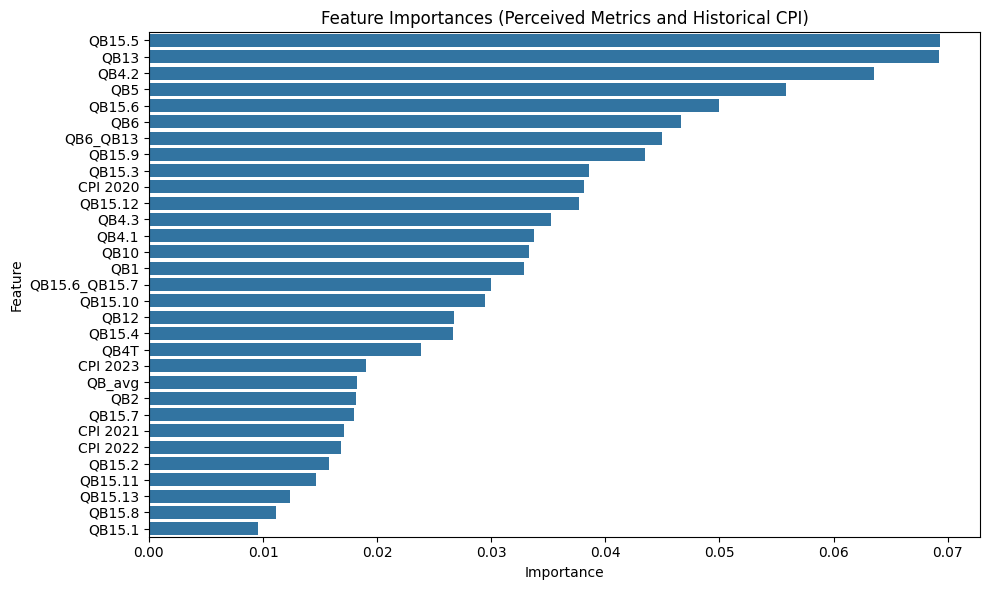

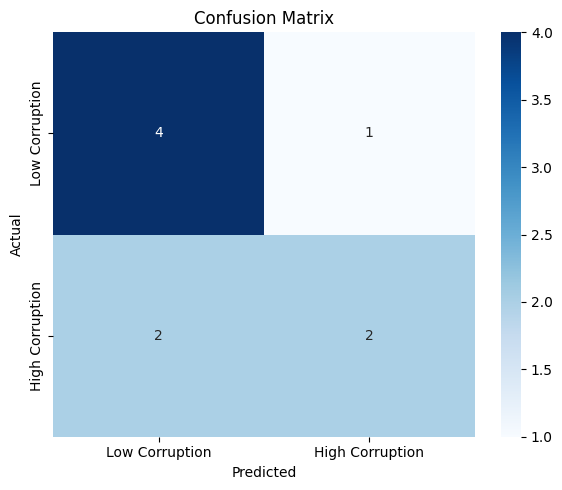

In [17]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Crear target variable: Niveles de corrupción (alta o baja corrupción)
data['Target'] = (data['df_totalscore'] > data['df_totalscore'].median()).astype(int)  # 1: Alta corrupción, 0: Baja corrupción

# Definir características: métricas percibidas y CPI históricos
perceived_corruption_cols = [col for col in data.columns if col.startswith('QB')]
cpi_columns = ['CPI 2020', 'CPI 2021', 'CPI 2022', 'CPI 2023']

# Crear conjunto de características (X)
X = data[perceived_corruption_cols + cpi_columns].fillna(0)

# Crear target (y)
y = data['Target']

# Dividir datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Ajustar modelo de Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Realizar predicciones
predictions = rf_model.predict(X_test)

# Evaluar modelo
conf_matrix = confusion_matrix(y_test, predictions)
class_report = classification_report(y_test, predictions)

# Importancia de características
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Mostrar resultados
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)
print("\nFeature Importances:")
print(feature_importances)

# Visualizar importancia de características
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances['Importance'], y=feature_importances['Feature'])
plt.title("Feature Importances (Perceived Metrics and Historical CPI)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Visualizar matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Low Corruption", "High Corruption"], yticklabels=["Low Corruption", "High Corruption"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Conclusions from the Model Results:

## 1. **What the Model is Predicting:**
   - The model predicts **current corruption levels** (real corruption), categorized as:
     - **Class 0:** Low corruption (below the median `df_totalscore`).
     - **Class 1:** High corruption (above the median `df_totalscore`).
   - Predictions are based on:
     - **Perceived corruption metrics** (e.g., QB questions, attitudes, and trends).
     - **Historical CPI data** (2020-2023), capturing objective measures of corruption over time.

## 2. **Overall Model Performance:**
   - The model achieves an **accuracy of 67%**, showing a moderate improvement compared to random guessing (50%).
   - **Class 0 (Low corruption):**
     - The model performs relatively well, achieving an F1-score of **0.73**, indicating better precision and recall for this class.
   - **Class 1 (High corruption):**
     - The model struggles to predict high corruption levels, with an F1-score of **0.57**, indicating challenges in distinguishing these cases.

## 3. **Key Predictors:**
   - **QB15.5 (Attitudes toward corruption):** The most important feature, indicating that societal acceptance or rejection of corruption strongly influences real corruption levels.
   - **QB13 (Reporting corruption):** Highlights the role of public willingness to report corruption as a key factor.
   - **QB4.2 (Perceptions of corruption):** Reflects general attitudes toward corruption in specific contexts.
   - **QB6 (Trends in corruption):** Perceived increases or decreases in corruption significantly correlate with real corruption levels.
   - **CPI 2020:** Among the historical CPI data, this year contributes most to the model, although its importance is limited compared to perceived corruption metrics.

## 4. **Contribution of Historical CPI Data:**
   - While CPI data is included, its combined importance is lower compared to perceived metrics.
   - **CPI 2020-2023** contributes to identifying real corruption trends but adds limited predictive value relative to other features.




